In [13]:
from math import log
from math import exp , e
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [14]:
pd.set_option('display.precision', 2)

In [15]:
study_df = pd.read_csv("C:/Users/leste/OneDrive/Desktop/Microsoft VS Code/Github/Data-Science-Portfolio/Data Files/Logistic Regression/study_dataset.csv")

In [16]:
study_df

,Studied,Slept,Passed
0,4.86,9.64,1
1,8.63,0.06,0
2,3.83,0.72,0
3,7.15,3.90,1
4,6.48,8.20,1
...,...,...,...
95,0.02,2.66,0
96,7.63,7.41,1
97,3.68,5.05,0
98,7.48,6.06,1


In [17]:
study_df['Studied'] = study_df['Studied'].round(2)
study_df['Slept'] = study_df['Slept'].round(2)

Text(0.5, 0, 'Distribution Features : Slept')

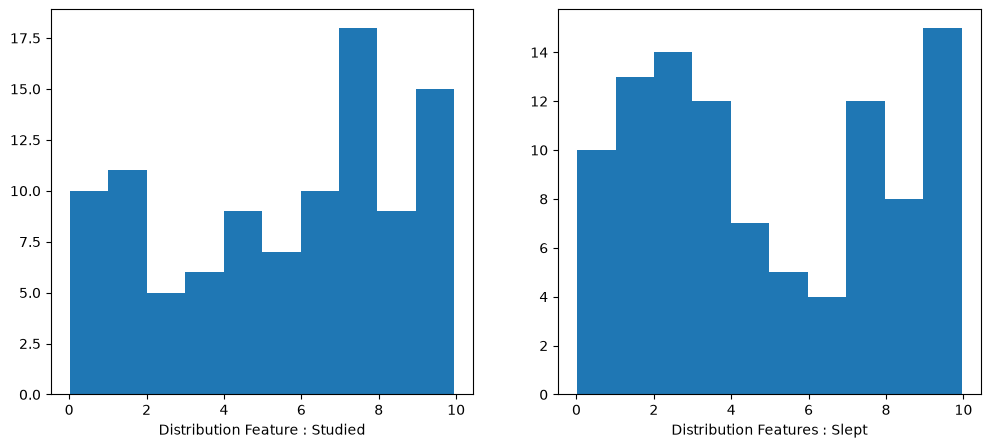

In [18]:
fig , ax = plt.subplots(1,2,figsize = (12,5))

ax[0].hist(study_df['Studied'])
ax[0].set_xlabel("Distribution Feature : Studied")

ax[1].hist(study_df['Slept'])
ax[1].set_xlabel("Distribution Features : Slept")



<Axes: xlabel='Slept', ylabel='Studied'>

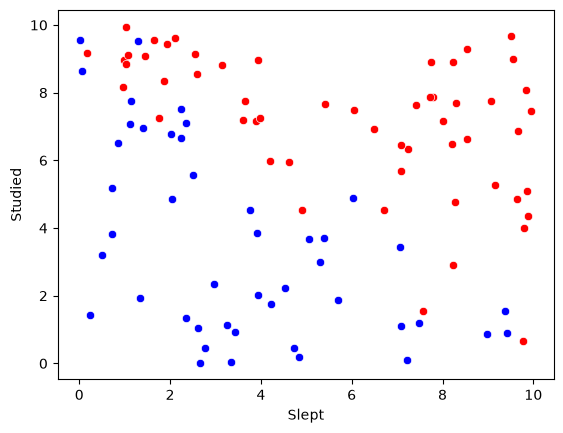

In [19]:
x_passed = study_df[study_df['Passed'] == 1]['Slept']
y_passed = study_df[study_df['Passed'] == 1]['Studied']

x_failed = study_df[study_df['Passed'] == 0]['Slept']
y_failed = study_df[study_df['Passed'] == 0]['Studied']

sns.scatterplot(x = x_passed, y = y_passed, color = 'red')

sns.scatterplot(x = x_failed , y = y_failed , color = 'blue')


> The Decision Boundary can be observed in the middle

In [20]:
def sigmoid_function(z):
    return 1 / (1 + e**-z)

In [21]:
study_df 

,Studied,Slept,Passed
0,4.86,9.64,1
1,8.63,0.06,0
2,3.83,0.72,0
3,7.15,3.90,1
4,6.48,8.20,1
...,...,...,...
95,0.02,2.66,0
96,7.63,7.41,1
97,3.68,5.05,0
98,7.48,6.06,1


In [22]:
x_features = study_df[['Studied','Slept']]
y_features = study_df[['Passed']]

In [23]:
stand = StandardScaler()

In [ ]:
x_stand = stand.fit_transform(x_features)

In [35]:
x_train , x_temp , y_train , y_temp = train_test_split(x_stand,np.array(y_features), test_size  = 0.2 , random_state = 42)
x_val , x_test , y_val , y_test = train_test_split(x_temp, y_temp , test_size= 0.4 , random_state = 50)

In [36]:
def logistic_cost_function(w,b,x,y): 

    m = x.shape[0]# training examples 
    cost = 0
    for t_e in range(m): #t_e stands for training examples
        z = np.dot(w,x[t_e]) + b
        f_w_b = sigmoid_function(z)
        cost += -y[t_e]*np.log(f_w_b) -(1-y[t_e])*np.log(1-f_w_b)
    
    cost = cost / m
    return cost


In [37]:
np.log(11)

np.float64(2.3978952727983707)

In [38]:
e**np.log(11) 

np.float64(11.0)

In [39]:
logistic_cost_function(0.01,2,x_train,y_train) # Total Cost

array([0.97429226, 0.97506159])

In [40]:
def calculate_gradient(w,b,x,y):

    m,n = x.shape
    dj_dw = 0
    dj_db = 0
    for i in range(m):
        z = np.dot(w,x[i]) + b
        fw_b = sigmoid_function(z)
        error = fw_b - y[i]
        for j in range(n-1):
            dj_dw_d = error*x[i,j]
            dj_db_d = error  
            dj_dw = dj_dw +  dj_dw_d 
            dj_db = dj_db + dj_db_d 
    dj_dw = dj_dw / m
    dj_db = dj_db / m 

    return dj_dw.astype(float) , dj_db.astype(float)
   

In [41]:
X_tmp = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_tmp = np.array([0, 0, 0, 1, 1, 1])
w_tmp = np.array([1.5,1.2])
b_tmp = 1.

In [42]:
def gradient_descent(w,b,x,y,num_iters,alpha):

    cost_history = []
    dj_dw , dj_db = calculate_gradient(w,b,x,y)

    for i in range(num_iters):
        w = w - alpha*dj_dw
        b = b - alpha*dj_db

        if i<10000:
            cost_history.append(logistic_cost_function(w,b,x,y))
    
        if i%math.ceil(num_iters/10) == 0 :
            print(f"Iteration {i : 3d} , Values {w} and {b} ,Cost History {cost_history[-1]}")

    return w,b, cost_history , print(min(cost_history))





In [43]:
gradient_descent(w_tmp,b_tmp,x_train,y_train,1000,0.01)

Iteration   0 , Values [1.50062057 1.20062057] and [0.99905917] ,Cost History [0.37648128]
Iteration  100 , Values [1.56267711 1.26267711] and [0.90497602] ,Cost History [0.36119566]
Iteration  200 , Values [1.62473365 1.32473365] and [0.81089287] ,Cost History [0.34810735]
Iteration  300 , Values [1.6867902 1.3867902] and [0.71680972] ,Cost History [0.33711679]
Iteration  400 , Values [1.74884674 1.44884674] and [0.62272657] ,Cost History [0.32813099]
Iteration  500 , Values [1.81090328 1.51090328] and [0.52864342] ,Cost History [0.32106307]
Iteration  600 , Values [1.87295983 1.57295983] and [0.43456027] ,Cost History [0.31583163]
Iteration  700 , Values [1.93501637 1.63501637] and [0.34047713] ,Cost History [0.31235989]
Iteration  800 , Values [1.99707291 1.69707291] and [0.24639398] ,Cost History [0.31057488]
Iteration  900 , Values [2.05912946 1.75912946] and [0.15231083] ,Cost History [0.31040673]
[0.31028433]


(array([2.12056544, 1.82056544]),
 array([0.05916851]),
 [array([0.37648128]),
  array([0.37631721]),
  array([0.37615336]),
  array([0.37598975]),
  array([0.37582636]),
  array([0.3756632]),
  array([0.37550028]),
  array([0.37533758]),
  array([0.37517512]),
  array([0.37501288]),
  array([0.37485087]),
  array([0.37468909]),
  array([0.37452754]),
  array([0.37436622]),
  array([0.37420513]),
  array([0.37404427]),
  array([0.37388363]),
  array([0.37372322]),
  array([0.37356305]),
  array([0.3734031]),
  array([0.37324338]),
  array([0.37308388]),
  array([0.37292462]),
  array([0.37276558]),
  array([0.37260677]),
  array([0.37244819]),
  array([0.37228984]),
  array([0.37213171]),
  array([0.37197381]),
  array([0.37181614]),
  array([0.37165869]),
  array([0.37150148]),
  array([0.37134449]),
  array([0.37118772]),
  array([0.37103118]),
  array([0.37087487]),
  array([0.37071879]),
  array([0.37056293]),
  array([0.3704073]),
  array([0.37025189]),
  array([0.37009671]),
  ar

In [44]:
model = LogisticRegression()

In [45]:
y_train

array([[0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1]])

In [46]:
model.fit(x_train,y_train)

c:\Users\leste\OneDrive\Desktop\Microsoft VS Code\Github\Data-Science-Portfolio\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [50]:
model.score(x_train,y_train)

0.875

In [52]:
y_pred = model.predict(x_val)

In [54]:
model.coef_

array([[2.25869593, 1.84328941]])

In [55]:
model.intercept_

array([0.44676088])

In [53]:
model.score(x_val,y_val)

0.9166666666666666